# AR tuning across sample sizes and fresh-path validation

This notebook preserves two extensions to the [unified tuning experiments](ar_unified_tuning_experiments.ipynb): tune one common schedule across $T\in\{500,2000\}$, then freeze the selected setting and compare it with a fixed baseline on separate validation paths. The baseline is the absolute setting $\gamma_0=0.7$, $H=50$ selected by the unified notebook's 20-path experiment at the time this extension was prepared.

Use the same AR(3) model $\phi=(0.6,-0.3,0.2)$, $U(-1,1)$ innovations, four-coordinate newest-first windows, one fixed starting direction, 2,000-evaluation cap, patience 200, strict improvement, scale grid $0.1,\ldots,0.9$, and half-life grid as the unified notebook. Normalization uses the actual cloud diameter. Selection uses achieved minimum widths. [Shared implementation](../ar_tools/tuning.py), `tune_ar_sample_sizes` and `compare_ar_schedules`.

The sample-size and validation comparisons are additional experimental design choices. The underlying geometric schedule and stopping rule follow the [thesis's AR tuning section](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex). No thesis source is changed. Tables stay in the notebook; displayed figures are also saved as PDF and PNG.

In [1]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_ar_sample_sizes, compare_ar_schedules, summarize_geometric_replications,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_tuning_sample_size_and_validation"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"


## Fixed settings

Six tuning paths and six separate validation paths are used as a small pilot. Each replication simulates one path of length 2,000; its first 500 observations form the smaller sample, so the sample sizes are paired. The tuning and validation seed streams are separate. All candidates use the same starting direction, including across phases. Only innovations and the retained prefix length vary.

The baseline below is frozen before validation. If the unified experiment is later rerun with different settings, updating this baseline is an explicit experimental choice. Validation results never revise the selected configuration. [Path generation and frozen-schedule evaluation](../ar_tools/tuning.py).

In [2]:
phi = np.array([0.6, -0.3, 0.2], dtype=float)
T_values = np.array([500, 2000], dtype=int)
burnin = 2000
optimizer_seed = 20261019
tuning_process_seed = 20261021
validation_process_seed = 20261022
tuning_replications = 6
validation_replications = 6
max_iterations = 2000
patience = 200
improvement_tolerance = 0.0
scale_grid = np.arange(1, 10) / 10.0
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])
baseline_schedule = {"candidate_id": "baseline", "step_rule": "absolute",
                     "step_value": 0.7, "half_life": 50.0}
if tuning_process_seed == validation_process_seed:
    raise ValueError("Use separate tuning and validation process-seed streams.")
initial_direction = np.random.default_rng(optimizer_seed).normal(size=len(phi) + 1)
initial_direction /= np.linalg.norm(initial_direction)
configuration = {
    "phi": phi.tolist(), "T_values": T_values.tolist(), "burnin": burnin,
    "optimizer_seed": optimizer_seed, "initial_direction": initial_direction.tolist(),
    "tuning_process_seed": tuning_process_seed, "validation_process_seed": validation_process_seed,
    "tuning_replications": tuning_replications, "validation_replications": validation_replications,
    "max_iterations": max_iterations, "patience": patience,
    "improvement_tolerance": improvement_tolerance,
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "baseline": baseline_schedule,
    "selection": "smallest mean achieved minimum width across all tuning cases",
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ["functions.py", "innovations.py", "descent.py", "tuning.py"]
    )).hexdigest(),
}
run_id = hashlib.sha256(repr(sorted(configuration.items())).encode()).hexdigest()[:16]
PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / run_id
IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / run_id
for directory in (PDF_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Run {run_id}; sample sizes={T_values}; fixed start={initial_direction}")
print("Frozen baseline:", baseline_schedule)

Run 623b1afb1e2421f0; sample sizes=[ 500 2000]; fixed start=[ 0.0469043  -0.81156153  0.31282302  0.49123275]
Frozen baseline: {'candidate_id': 'baseline', 'step_rule': 'absolute', 'step_value': 0.7, 'half_life': 50.0}


## Tune across both sample sizes

Every candidate is evaluated on every tuning path at each sample size. Select the smallest mean achieved minimum width across all $6\times2$ cases, with equal weight per case. For each sample size, also show its own ranking to inspect whether the preferred schedule changes with $T$. Exact ties use mean evaluations and then parameter labels. [Ranking implementation](../ar_tools/tuning.py), `summarize_geometric_replications`.

In [3]:
sample_size_experiment = tune_ar_sample_sizes(
    phi, T_values, initial_direction, scale_grid, half_life_grid,
    replications=tuning_replications, process_seed=tuning_process_seed, burnin=burnin,
    iterations=max_iterations, patience=patience, improvement_tolerance=improvement_tolerance,
    optimizer_seed=optimizer_seed, progress=True,
)
tuning_results = pd.DataFrame(sample_size_experiment["results"])
tuning_cases = pd.DataFrame(sample_size_experiment["cases"])
joint_ranking = pd.DataFrame(sample_size_experiment["ranking"])
selected_schedule = {
    key: sample_size_experiment["selected"][key]
    for key in ("step_rule", "step_value", "half_life")
}
selected_schedule["candidate_id"] = "selected"
rankings_by_T = pd.concat([
    pd.DataFrame(summarize_geometric_replications(
        tuning_results.loc[tuning_results["T"] == T].to_dict("records"),
    )).assign(T=int(T))
    for T in T_values
], ignore_index=True)
summary_columns = ["rank", "step_rule", "step_value", "half_life", "beta",
                   "replications", "cases", "mean_minimum_width", "mean_evaluations"]
with pd.option_context("display.max_columns", None, "display.precision", 10):
    print("Joint ranking over all tuning paths and sample sizes:")
    display(joint_ranking[summary_columns].head(10))
    print("Top configurations at each sample size:")
    display(rankings_by_T.groupby("T", sort=True).head(5)[["T", *summary_columns]])
print("Selected setting, frozen before validation:", selected_schedule)

Path 1/6, T=500: best achieved width=1.5957116044, L=4.60201, 144 schedules; 1.8s
Path 1/6, T=2000: best achieved width=1.6316519999, L=5.2134, 144 schedules; 3.2s
Path 2/6, T=500: best achieved width=1.6211668728, L=5.3641, 144 schedules; 1.9s
Path 2/6, T=2000: best achieved width=1.6282917588, L=5.38455, 144 schedules; 2.6s
Path 3/6, T=500: best achieved width=1.5676403733, L=5.07401, 144 schedules; 1.5s
Path 3/6, T=2000: best achieved width=1.6316677503, L=5.65901, 144 schedules; 2.9s
Path 4/6, T=500: best achieved width=1.5967908719, L=4.82161, 144 schedules; 1.9s
Path 4/6, T=2000: best achieved width=1.6189269282, L=5.34651, 144 schedules; 2.8s
Path 5/6, T=500: best achieved width=1.5836864936, L=4.2545, 144 schedules; 1.7s
Path 5/6, T=2000: best achieved width=1.6261230371, L=5.48736, 144 schedules; 2.8s
Path 6/6, T=500: best achieved width=1.6318576536, L=4.63491, 144 schedules; 2.1s
Path 6/6, T=2000: best achieved width=1.6344454288, L=5.42266, 144 schedules; 2.8s
Joint ranking

,rank,step_rule,step_value,half_life,beta,replications,cases,mean_minimum_width,mean_evaluations
0,1,absolute,0.6,50.0,0.9862327045,6,12,1.6140044660,1894.3333333333
1,2,absolute,0.8,100.0,0.9930924954,6,12,1.6140190179,1702.4166666667
2,3,diameter_normalized,0.9,100.0,0.9930924954,6,12,1.6140684717,1645.5000000000
3,4,absolute,0.2,100.0,0.9930924954,6,12,1.6141514993,1707.4166666667
4,5,absolute,0.9,50.0,0.9862327045,6,12,1.6142301785,1880.8333333333
5,6,absolute,0.8,50.0,0.9862327045,6,12,1.6143269058,2000.0000000000
6,7,absolute,0.7,50.0,0.9862327045,6,12,1.6143682319,2000.0000000000
7,8,absolute,0.9,20.0,0.9659363289,6,12,1.6144067895,1215.9166666667
8,9,absolute,0.3,50.0,0.9862327045,6,12,1.6144138867,2000.0000000000
9,10,absolute,0.4,50.0,0.9862327045,6,12,1.6144378943,2000.0000000000


,T,rank,step_rule,step_value,half_life,beta,replications,cases,mean_minimum_width,mean_evaluations
0,500,1,absolute,0.8,100.0,0.9930924954,6,6,1.5994768829,1810.0000000000
1,500,2,absolute,0.6,50.0,0.9862327045,6,6,1.5994775005,1788.6666666667
2,500,3,diameter_normalized,0.9,100.0,0.9930924954,6,6,1.5996181587,1536.0000000000
3,500,4,absolute,0.2,100.0,0.9930924954,6,6,1.5997681622,1642.3333333333
4,500,5,absolute,0.9,50.0,0.9862327045,6,6,1.5999203656,2000.0000000000
144,2000,1,diameter_normalized,0.8,100.0,0.9930924954,6,6,1.6285184103,1936.5000000000
145,2000,2,absolute,0.4,100.0,0.9930924954,6,6,1.6285184172,1950.8333333333
146,2000,3,absolute,0.7,100.0,0.9930924954,6,6,1.6285186097,1993.8333333333
147,2000,4,diameter_normalized,0.9,100.0,0.9930924954,6,6,1.6285187847,1755.0000000000
148,2000,5,absolute,0.9,100.0,0.9930924954,6,6,1.6285187960,1922.6666666667


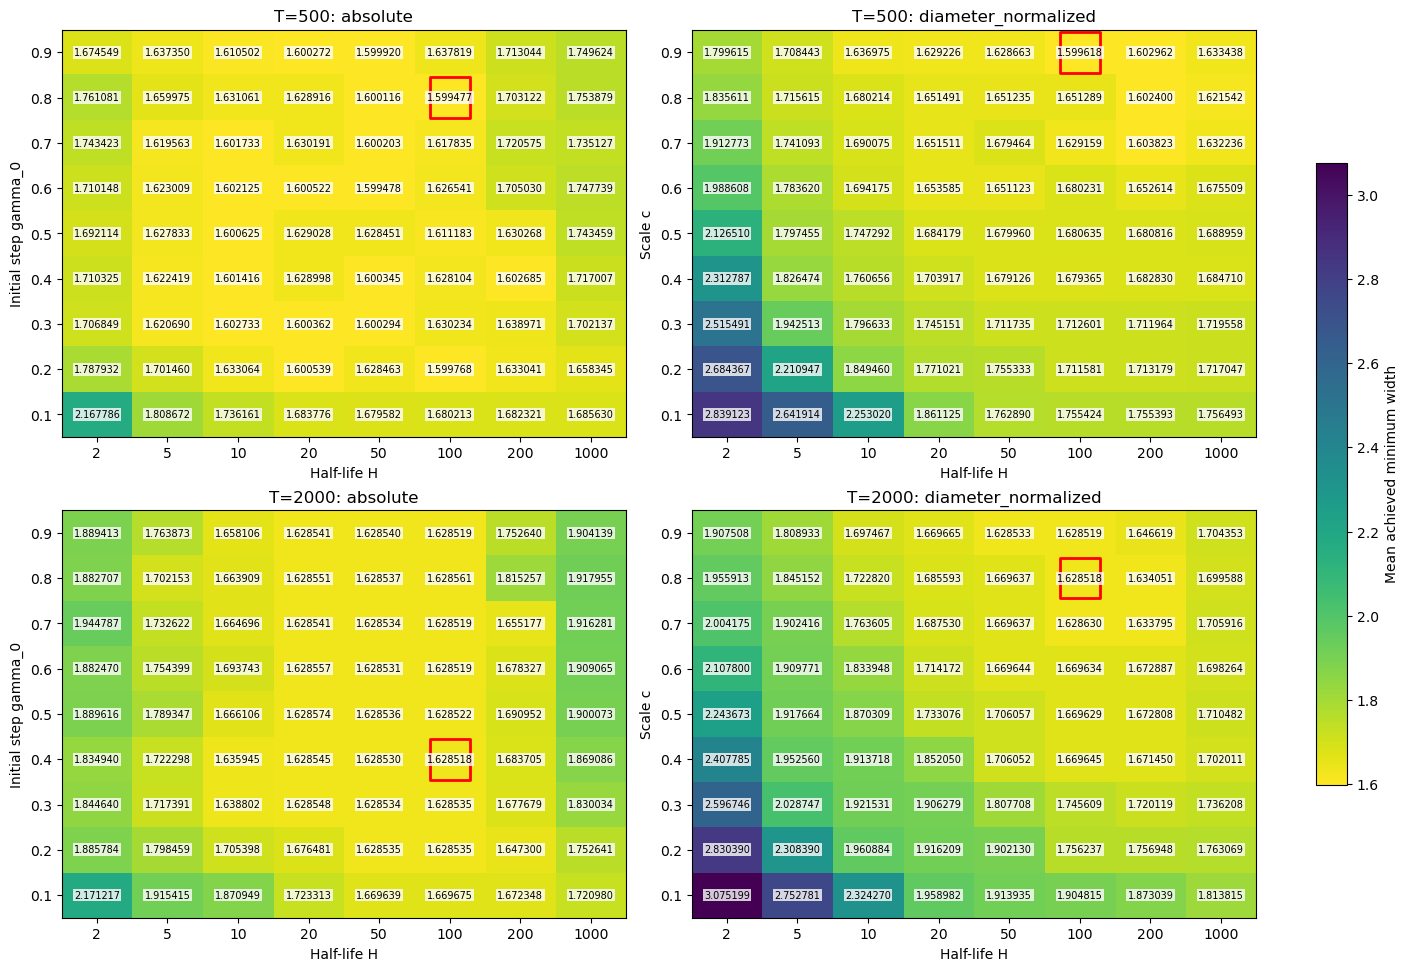

In [4]:
fig, axes = plt.subplots(len(T_values), 2, squeeze=False,
                         figsize=(14, 4.8 * len(T_values)), constrained_layout=True)
color_min = rankings_by_T["mean_minimum_width"].min()
color_max = rankings_by_T["mean_minimum_width"].max()
for line, T in enumerate(T_values):
    for column, rule in enumerate(("absolute", "diameter_normalized")):
        rows = rankings_by_T.loc[(rankings_by_T["T"] == T) & (rankings_by_T["step_rule"] == rule)]
        matrix = rows.pivot(index="step_value", columns="half_life", values="mean_minimum_width").reindex(
            index=scale_grid, columns=half_life_grid,
        )
        ax = axes[line, column]
        image = ax.imshow(matrix.to_numpy(), origin="lower", aspect="auto", cmap="viridis_r",
                          vmin=color_min, vmax=color_max)
        for i in range(len(scale_grid)):
            for j in range(len(half_life_grid)):
                ax.text(j, i, f"{matrix.iloc[i,j]:.6f}", ha="center", va="center", fontsize=7,
                        bbox={"facecolor": "white", "alpha": 0.78, "edgecolor": "none", "pad": 1})
        best = rows.iloc[0]
        ax.scatter(np.flatnonzero(half_life_grid == best["half_life"])[0],
                   np.flatnonzero(scale_grid == best["step_value"])[0],
                   marker="s", s=850, facecolors="none", edgecolors="red", linewidths=2)
        ax.set(xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
               yticks=np.arange(len(scale_grid)), yticklabels=[f"{s:g}" for s in scale_grid],
               xlabel="Half-life H", ylabel="Initial step gamma_0" if rule == "absolute" else "Scale c",
               title=f"T={T}: {rule}")
fig.colorbar(image, ax=axes.ravel().tolist(), label="Mean achieved minimum width", shrink=0.7)
save_figure(fig, "01_sample_size_width_matrices", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR)
plt.show()
plt.close(fig)

## Validate the frozen selection on fresh paths

Evaluate the selected schedule and the fixed baseline on six fresh paths at both sample sizes. Both schedules share each cloud and starting direction. Report their achieved widths and the paired difference (selected minus baseline); negative values favor the selected setting. This phase performs no parameter search. If the schedules coincide, their numerical results must agree. [Frozen-schedule implementation](../ar_tools/tuning.py), `compare_ar_schedules`.

In [5]:
validation_experiment = compare_ar_schedules(
    phi, T_values, initial_direction, [selected_schedule, baseline_schedule],
    replications=validation_replications, process_seed=validation_process_seed, burnin=burnin,
    iterations=max_iterations, patience=patience, improvement_tolerance=improvement_tolerance,
    optimizer_seed=optimizer_seed, progress=True,
)
validation_results = pd.DataFrame(validation_experiment["results"])
assert set(tuning_cases["process_seed"]).isdisjoint(set(validation_results["process_seed"]))
validation_summary = validation_results.groupby(["T", "candidate_id"], sort=True).agg(
    mean_minimum_width=("minimum_width", "mean"),
    median_minimum_width=("minimum_width", "median"),
    mean_evaluations=("total_evaluations", "mean"),
    gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
).reset_index()
paired_comparison = validation_results.pivot(index=["replication", "T"],
                                            columns="candidate_id", values="minimum_width").reset_index()
paired_comparison["selected_minus_baseline"] = paired_comparison["selected"] - paired_comparison["baseline"]
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(validation_summary)
    display(paired_comparison)
print("Selection remains frozen:", selected_schedule)

Fresh path 1/6, T=500: evaluated 2 frozen schedules
Fresh path 1/6, T=2000: evaluated 2 frozen schedules
Fresh path 2/6, T=500: evaluated 2 frozen schedules
Fresh path 2/6, T=2000: evaluated 2 frozen schedules
Fresh path 3/6, T=500: evaluated 2 frozen schedules
Fresh path 3/6, T=2000: evaluated 2 frozen schedules
Fresh path 4/6, T=500: evaluated 2 frozen schedules
Fresh path 4/6, T=2000: evaluated 2 frozen schedules
Fresh path 5/6, T=500: evaluated 2 frozen schedules
Fresh path 5/6, T=2000: evaluated 2 frozen schedules
Fresh path 6/6, T=500: evaluated 2 frozen schedules
Fresh path 6/6, T=2000: evaluated 2 frozen schedules
Selection remains frozen: {'step_rule': 'absolute', 'step_value': 0.6, 'half_life': 50.0, 'candidate_id': 'selected'}


,T,candidate_id,mean_minimum_width,median_minimum_width,mean_evaluations,gamma0_min,gamma0_max
0,500,baseline,1.6316747664,1.6171988883,2000.0,0.7,0.7
1,500,selected,1.6317211988,1.6171989115,2000.0,0.6,0.6
2,2000,baseline,1.6735997364,1.6321695924,2000.0,0.7,0.7
3,2000,selected,1.6316226815,1.6308189631,2000.0,0.6,0.6


candidate_id,replication,T,baseline,selected,selected_minus_baseline
0,1,500,1.6106159114,1.6106159577,4.6295669520e-08
1,1,2000,1.6298605779,1.6298605779,1.4654943925e-14
2,2,500,1.6237818653,1.6237818653,-2.4957813594e-13
3,2,2000,1.6342880413,1.6342890139,9.7267786514e-07
4,3,500,1.5667739576,1.5667739576,-3.4638958368e-14
5,3,2000,1.8834061851,1.6315867827,-2.5181940244e-01
6,4,500,1.5967347170,1.5967347170,-1.5099033135e-14
7,4,2000,1.6354269357,1.6353476224,-7.9313256359e-05
8,5,500,1.6750334343,1.6750334343,-7.5495165675e-15
9,5,2000,1.6285655352,1.6286009487,3.5413476978e-05


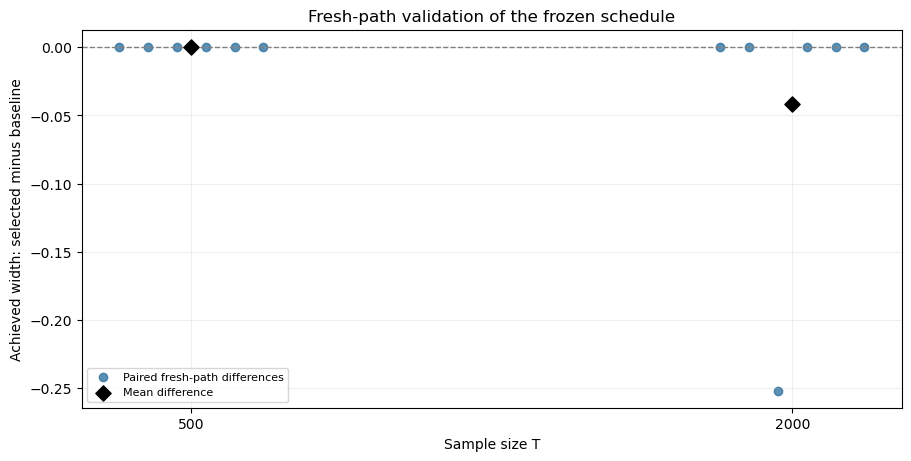

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for index, T in enumerate(T_values):
    values = paired_comparison.loc[paired_comparison["T"] == T, "selected_minus_baseline"].to_numpy()
    jitter = np.linspace(-0.12, 0.12, len(values))
    ax.scatter(index + jitter, values, color="#3274A1", alpha=0.8,
               label="Paired fresh-path differences" if index == 0 else None)
    ax.scatter(index, values.mean(), color="black", marker="D", s=60,
               label="Mean difference" if index == 0 else None, zorder=3)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set(xticks=np.arange(len(T_values)), xticklabels=[f"{T:g}" for T in T_values],
       xlabel="Sample size T", ylabel="Achieved width: selected minus baseline",
       title="Fresh-path validation of the frozen schedule")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
save_figure(fig, "02_fresh_path_validation", pdf_directory=PDF_DIR, image_directory=IMAGE_DIR)
plt.show()
plt.close(fig)

## Scope and retained outputs

The selected joint setting and all per-case widths remain in memory and in the saved notebook outputs. Only PDF and PNG figures are exported. The study uses no JSON/CSV exports, resume caches, external optimum calculations, gap targets or alternative step-size schedules.

These comparisons concern one coefficient vector and one starting direction. They do not implement the thesis's third tuning experiment over different coefficient vectors, or a separate random-start sensitivity study. The pilot validation sample does not revise the frozen selection. [Experiment scope](../ar_tools/tuning.py).

In [7]:
print("Frozen joint selection:", selected_schedule)
print(f"Mean achieved tuning width across all sizes: {joint_ranking.iloc[0]['mean_minimum_width']:.12g}")
print("Fresh-path validation means:")
display(paired_comparison.groupby("T")["selected_minus_baseline"].mean().rename("mean_width_difference"))
print(f"PDF figures: {PDF_DIR}")

Frozen joint selection: {'step_rule': 'absolute', 'step_value': 0.6, 'half_life': 50.0, 'candidate_id': 'selected'}
Mean achieved tuning width across all sizes: 1.61400446605
Fresh-path validation means:
PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_tuning_sample_size_and_validation/623b1afb1e2421f0


T
500     0.000046
2000   -0.041977
Name: mean_width_difference, dtype: float64